In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
import zipfile
from zipfile import ZipFile

In [3]:
#%pip install opencv-python

In [4]:
import cv2

In [5]:
os.listdir()

['cnn_binary_image.ipynb', '.ipynb_checkpoints']

In [6]:
os.getcwd()

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/notebooks'

In [7]:
data_dir = "/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data"

os.listdir(data_dir)

['CATDOG', 'cw3_housing_data_part_b.xlsx', 'CATDOG.zip']

In [8]:
path = os.path.join(data_dir, 'CATDOG.zip')

In [9]:
#with zipfile.ZipFile(path, 'r') as data: #extracting the zip folder in the same path
 #   data.extractall(data_dir)
    

In [10]:
os.listdir(data_dir)

['CATDOG', 'cw3_housing_data_part_b.xlsx', 'CATDOG.zip']

In [11]:
#for root, dirs, files in os.walk(data_dir):
 #   print(root)
  ##  for file in files:
    #    print("   └──", file)

In [12]:
way = data_dir + '/CATDOG'

In [13]:
way

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG'

In [14]:
os.listdir(way)

['training_set', 'test_set']

In [15]:
test_dir = way + '/test_set/'
train_dir = way + '/training_set/'

In [16]:
os.listdir(test_dir)

['dogs', 'cats']

In [17]:
os.listdir(train_dir)

['dogs', 'cats']

In [18]:
os.listdir(test_dir+'dogs')[0]

'dog.4159.jpg'

In [19]:
os.listdir(test_dir+'cats')[0]

'cat.4369.jpg'

In [20]:
os.listdir(train_dir+'dogs')[0]

'dog.1753.jpg'

In [21]:
mydog = test_dir+'dogs/'+os.listdir(test_dir+'dogs/')[7]
print(mydog)

/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG/test_set/dogs/dog.4818.jpg


No Color Correction


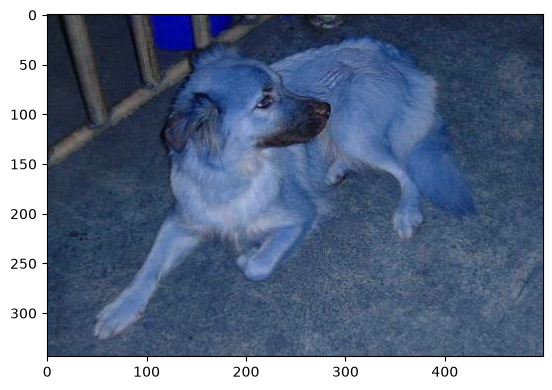

In [22]:
print('No Color Correction')
sample = cv2.imread(mydog)
plt.imshow(sample)


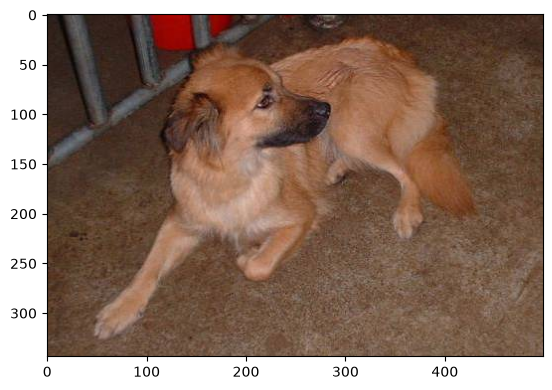

In [23]:
sample = cv2.imread(mydog)
sample = cv2.cvtColor(sample, cv2.COLOR_BGR2RGB)  #color correction
plt.imshow(sample) 

In [24]:
from matplotlib.image import imread #importing imread to replace cv2 for simplicity

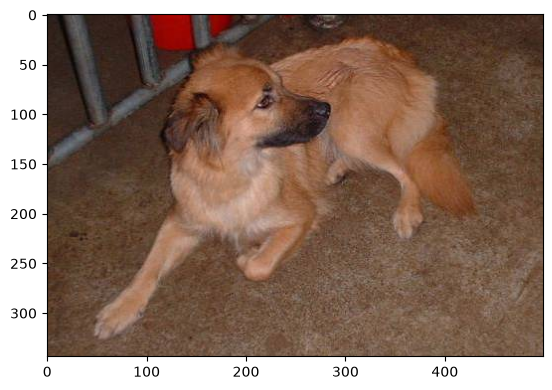

In [25]:
sample_matrix = imread(mydog)
plt.imshow(sample_matrix)   #unlike cv2, we do not have to color correct the images

In [26]:
sample_matrix.shape

(344, 499, 3)

In [27]:
test_dir +'dogs'

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/data/CATDOG/test_set/dogs'

In [28]:
shape_x = []                          #creating empty list for width of the images
shape_y = []                          #creating empty list for height of the images
color_channel = []                        #creating empty list for color channel of the images

for i in os.listdir(test_dir+'dogs'):     #running for loop in the dogs folder in test directory
  sample = imread(test_dir + 'dogs/'+i)   #selecting next image everytime    

  shape_x.append(sample.shape[0])               #adding widths in the list
  shape_y.append(sample.shape[1])               #adding hieght in the list
  color_channel.append(sample.shape[2])             #adding color channels in the list

In [29]:
min(shape_x), max(shape_x)

(33, 500)

In [30]:
min(shape_y), max(shape_y)

(92, 500)

In [31]:
min(color_channel), max(color_channel)

(3, 3)

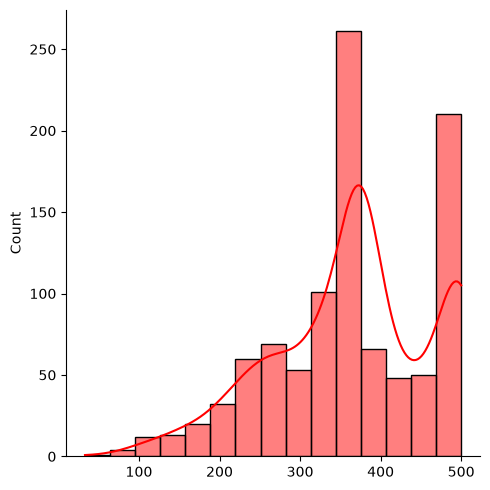

In [32]:
sns.displot(shape_x, bins=15, kde=True, color='red')

In [33]:
#importing other necessary libraries for sequential API model

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPool2D, Flatten,BatchNormalization,MaxPooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [34]:
#%pip install tensorflow

In [35]:
#making instances of IDG for training and testing

train_IDG=ImageDataGenerator(#width_shift_range= 0.3,  #width manipulation
                         #height_shift_range=0.1,   #heigth manipulation
                         #rotation_range=40,       #rotation enable
                         rescale = 1/255,       #rescaling the images ****VVI****
                         #horizontal_flip =True,   #flipping horizontally able
                         #fill_mode= 'nearest'
                       )
test_IDG=ImageDataGenerator(#width_shift_range= 0.3,
                        #height_shift_range=0.1,
                        rotation_range=40,
                       rescale = 1/255,
                       #horizontal_flip =True,
                       #fill_mode= 'nearest'
                       )


    

In [36]:
imageshape = (100,100)    #defining size of image
batchsize = 100        #defining batch size


In [37]:
print('In the training direcotry, we')

train_generator = train_IDG.flow_from_directory(train_dir,
                                               target_size=imageshape,
                                               color_mode='rgb',
                                               batch_size=batchsize,
                                               class_mode='binary')
print()
print('In the testing direcotry, we')

validation_data_set = test_IDG.flow_from_directory(test_dir,
                                             target_size=imageshape,
                                             color_mode='rgb',
                                             batch_size=batchsize,
                                             class_mode='binary',
                                               shuffle=False)


In the training direcotry, we
Found 8020 images belonging to 2 classes.

In the testing direcotry, we
Found 2000 images belonging to 2 classes.


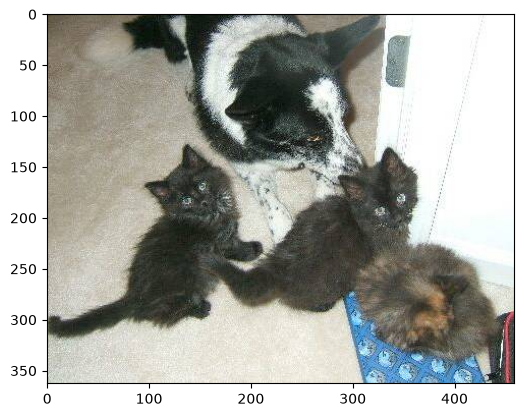

In [38]:
mycat = imread(test_dir+'/cats/cat.4104.jpg')  #reading the image from 'cats' folder and storing under my_cat
plt.imshow(mycat)        #visualising the image

These are some of the possible ways that IDG manipulates the images fed to the model


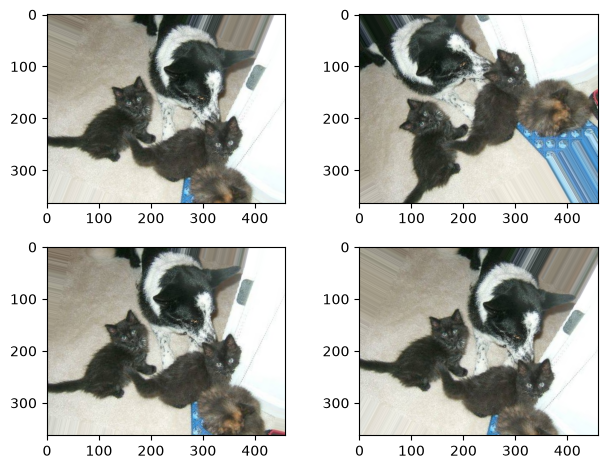

In [39]:
#visualizing what the instance made above does to the input image

fig, ax = plt.subplots(2,2)
plt.tight_layout()

#possibilities
ax[0][0].imshow(test_IDG.random_transform(mycat))
ax[0][1].imshow(test_IDG.random_transform(mycat))
ax[1][1].imshow(test_IDG.random_transform(mycat))
ax[1][0].imshow(test_IDG.random_transform(mycat))

print('These are some of the possible ways that IDG manipulates the images fed to the model')

In [40]:
mymodel = Sequential()

mymodel.add(Conv2D(32, kernel_size=(3,3),padding='valid', activation ='relu', input_shape=(100,100,3) ))
mymodel.add(BatchNormalization())
mymodel.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

mymodel.add(Conv2D(64, kernel_size=(3,3), padding ='valid', activation ='relu', input_shape=(100,100,3)))
mymodel.add(BatchNormalization())
mymodel.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

mymodel.add(Conv2D(64, kernel_size=(3,3), padding ='valid', activation ='relu', input_shape=(100,100,3)))
mymodel.add(BatchNormalization())
mymodel.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

mymodel.add(Flatten())

mymodel.add(Dense(64, activation='relu'))
mymodel.add(Dropout(0.4))

mymodel.add(Dense(1, activation='sigmoid'))

mymodel.summary()


/opt/anaconda3/envs/cnn-env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 98, 98, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 47, 47, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 21, 21, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 21, 21, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 466,689 (1.78 MB)

 Trainable params: 466,369 (1.78 MB)

 Non-trainable params: 320 (1.25 KB)

In [41]:
mymodel.compile(loss='binary_crossentropy',
                optimizer = 'adam',
                metrics=['accuracy'])


In [42]:
from tensorflow.keras.utils import plot_model

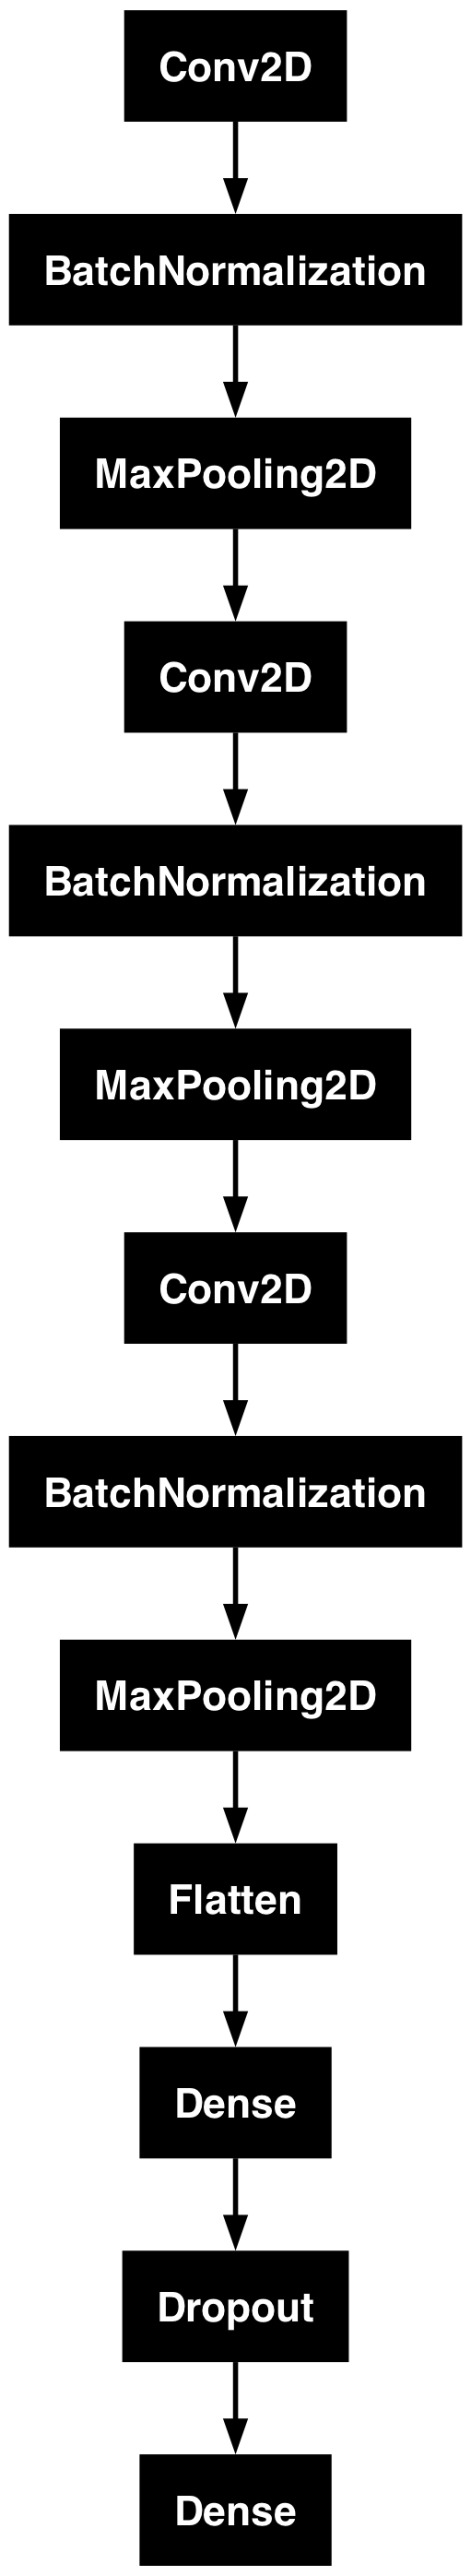

In [43]:

plot_model(mymodel)

In [44]:
#%pip install pydot

In [45]:
from tensorflow.keras.callbacks import EarlyStopping

In [46]:
es = EarlyStopping(monitor='val_loss', patience = 5)

In [48]:
train_generator.class_indices

{'cats': 0, 'dogs': 1}

In [49]:
validation_data_set.class_indices  #checking clas indices in test directory

{'cats': 0, 'dogs': 1}

In [51]:
#mymodelfit = mymodel.fit_generator(train_generator, 
#                                  epochs = 100,
#                                  validation_step = 100,
#                                  validation_data = validation_data_set,
 #                                 verbose = 1,
  #                                callbacks =[es])

In [53]:
#new models works with fit() rather than fit_generator()

mymodelfit = mymodel.fit(train_generator, 
                                  epochs = 100,
                                  validation_steps = 100,
                                  validation_data = validation_data_set,
                                  verbose = 1,
                                  callbacks =[es])

Epoch 1/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 21s 238ms/step - accuracy: 0.6464 - loss: 0.6509 - val_accuracy: 0.5095 - val_loss: 0.8416
Epoch 2/100


/opt/anaconda3/envs/cnn-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 229ms/step - accuracy: 0.7352 - loss: 0.5284 - val_accuracy: 0.4995 - val_loss: 1.3021
Epoch 3/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 240ms/step - accuracy: 0.7840 - loss: 0.4513 - val_accuracy: 0.5000 - val_loss: 1.4587
Epoch 4/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 240ms/step - accuracy: 0.8178 - loss: 0.4036 - val_accuracy: 0.5005 - val_loss: 0.9065
Epoch 5/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 241ms/step - accuracy: 0.8439 - loss: 0.3428 - val_accuracy: 0.5175 - val_loss: 1.2723
Epoch 6/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 240ms/step - accuracy: 0.8678 - loss: 0.3023 - val_accuracy: 0.6150 - val_loss: 0.7757
Epoch 7/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 19s 239ms/step - accuracy: 0.8953 - loss: 0.2477 - val_accuracy: 0.6180 - val_loss: 1.3443
Epoch 8/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 241ms/step - accuracy: 0.9153 - loss: 0.2006 - val_accuracy: 0.6330 - val_loss: 1.2534
Epoch 9/100
81/81 ━━━━━━━━━━━━━━━━━━━━ 20s 244ms/step - accuracy: 0.9360 - loss: 0.1582 - val_accuracy

<Axes: >

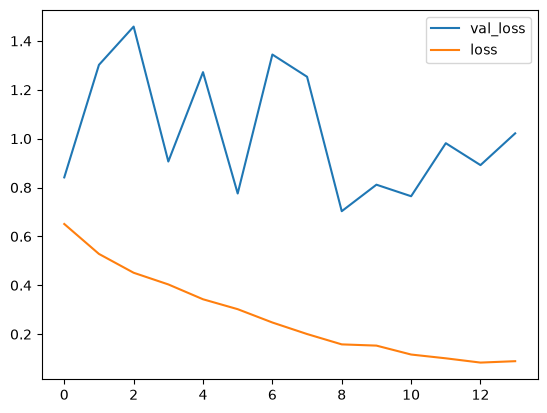

In [54]:
pd.DataFrame(mymodel.history.history)[['val_loss','loss']].plot()

<Axes: >

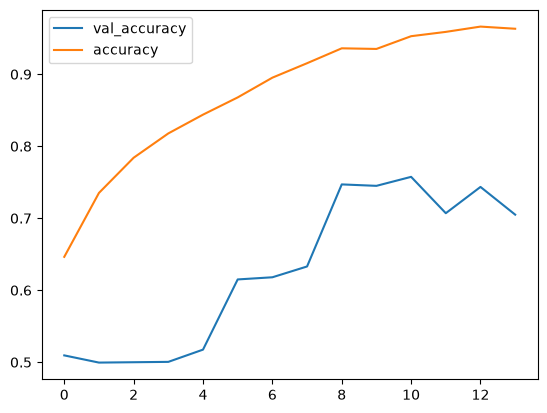

In [56]:
pd.DataFrame(mymodel.history.history)[['val_accuracy','accuracy']].plot()

In [57]:
#prediction = mymodel.predict_generator(validation_data_set)

AttributeError: 'Sequential' object has no attribute 'predict_generator'

In [58]:
prediction = mymodel.predict(validation_data_set)   

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step


In [59]:
prediction

array([[0.9766798 ],
       [0.97285396],
       [0.05069774],
       ...,
       [0.1571018 ],
       [0.85453016],
       [0.9553121 ]], shape=(2000, 1), dtype=float32)

In [63]:
prediction = prediction>0.5

In [64]:
validation_data_set.classes

array([0, 0, 0, ..., 1, 1, 1], shape=(2000,), dtype=int32)

In [65]:
(validation_data_set.classes, prediction)

(array([0, 0, 0, ..., 1, 1, 1], shape=(2000,), dtype=int32),
 array([[ True],
        [ True],
        [False],
        ...,
        [False],
        [ True],
        [ True]], shape=(2000, 1)))

In [66]:
from sklearn.metrics import classification_report, confusion_matrix

In [67]:
print(classification_report(validation_data_set.classes, prediction))

              precision    recall  f1-score   support

           0       0.84      0.54      0.66      1000
           1       0.66      0.90      0.76      1000

    accuracy                           0.72      2000
   macro avg       0.75      0.72      0.71      2000
weighted avg       0.75      0.72      0.71      2000



In [68]:
confused = confusion_matrix(validation_data_set.classes, prediction)
confused

array([[539, 461],
       [100, 900]])

<Axes: >

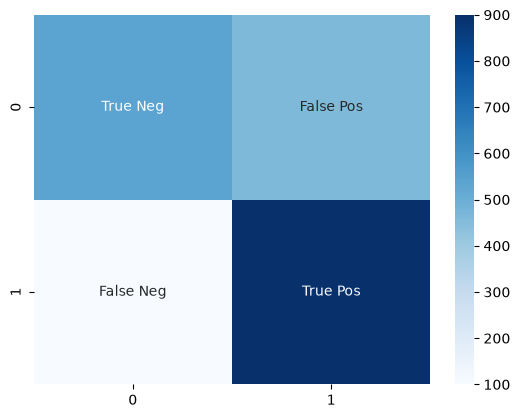

In [69]:
labels = ['True Neg','False Pos','False Neg','True Pos']
labels = np.asarray(labels).reshape(2,2)

sns.heatmap(confused, annot= labels, fmt='', cmap='Blues')

In [70]:
mymodel.save("classifier.keras")

In [71]:
os.getcwd()

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/notebooks'

In [72]:
os.listdir()

['cnn_binary_image.ipynb',
 'model.png',
 '.ipynb_checkpoints',
 'classifier.keras']

In [77]:
from flask import Flask, render_template, request
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import load_img, img_to_array
from pyngrok import ngrok
from werkzeug.utils import secure_filename
import uuid


In [79]:
app = Flask(__name__)

model = load_model("classifier.keras")



In [80]:
UPLOAD_FOLDER = "/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification/user"

os.makedirs(UPLOAD_FOLDER, exist_ok=True)

app.config["UPLOAD_FOLDER"] = UPLOAD_FOLDER

In [81]:
ALLOWED_EXTENSIONS = {"png", "jpg", "jpeg"}

def allowed_file(filename):
    return (
        "." in filename
        and filename.rsplit(".", 1)[1].lower() in ALLOWED_EXTENSIONS
    )

In [82]:
@app.route("/")
def home():
    return render_template("index.html")

In [83]:
@app.route("/predict", methods=["POST"])
def predict():

    if "image" not in request.files:
        return render_template("index.html", error="Please upload an image.")

    file = request.files["image"]

    if file.filename == "":
        return render_template("index.html", error="No image selected.")

    if not allowed_file(file.filename):
        return render_template("index.html", error="Please upload JPG or PNG.")

    try:
        # Generate unique filename
        extension = secure_filename(file.filename).rsplit(".", 1)[1].lower()
        filename = f"{uuid.uuid4().hex}.{extension}"

        # Save uploaded image
        image_path = os.path.join(app.config["UPLOAD_FOLDER"], filename)
        file.save(image_path)

        # Load and resize image
        img = load_img(image_path, target_size=(100, 100))

        # Convert image to array
        img_array = img_to_array(img)

        # Add batch dimension
        img_array = np.expand_dims(img_array, axis=0)

        # Normalise image
        img_array = img_array / 255.0

        # CNN prediction
        prediction = model.predict(img_array)

        probability = float(prediction[0][0])

        # Convert prediction into CAT or DOG
        if probability >= 0.5:
            result = "DOG"
            confidence = probability * 100
        else:
            result = "CAT"
            confidence = (1 - probability) * 100

        return render_template(
            "index.html",
            prediction=result,
            confidence=round(confidence, 2),
            image_name=filename
        )

    except Exception as e:
        return render_template("index.html", error=str(e))

In [84]:
from flask import send_from_directory

@app.route("/user/<filename>")
def uploaded_file(filename):
    return send_from_directory(app.config["UPLOAD_FOLDER"], filename)

In [91]:
os.chdir("/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification")

In [92]:
os.makedirs("static", exist_ok=True)

In [93]:
os.getcwd()

'/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification'

In [94]:
%%writefile templates/index.html

<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <title>Cat and Dog Classifier</title>
    <link rel="stylesheet" href="{{ url_for('static', filename='style.css') }}">
</head>
<body>

    <div class="container">
        <h1>Cat and Dog Image Classifier</h1>
        <p>Upload an image to classify it.</p>

        <form action="/predict" method="POST" enctype="multipart/form-data">
            <input type="file" name="image" accept="image/*" required>
            <button type="submit">Predict Image</button>
        </form>

        {% if prediction %}
            <div class="result">
                <h2>Prediction: {{ prediction }}</h2>
                <p>Confidence: {{ confidence }}%</p>

                <img src="{{ url_for('uploaded_file', filename=image_name) }}"
                     alt="Uploaded image" width="300">
            </div>
        {% endif %}
    </div>

</body>
</html>

Writing templates/index.html


In [95]:
%%writefile static/style.css

body {
    font-family: Arial, sans-serif;
    background: #f2f4f8;
    text-align: center;
    padding: 40px;
}

.container {
    background: white;
    max-width: 600px;
    margin: auto;
    padding: 35px;
    border-radius: 15px;
    box-shadow: 0 4px 15px rgba(0,0,0,0.1);
}

button {
    background: #2563eb;
    color: white;
    border: none;
    padding: 12px 25px;
    border-radius: 6px;
    cursor: pointer;
    margin-top: 15px;
}

.result {
    margin-top: 30px;
}

.result img {
    max-width: 100%;
    border-radius: 10px;
}

Writing static/style.css


In [96]:
for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints", "__pycache__"]]
    print(root, files)

. ['.DS_Store', '.gitignore']
./user []
./static ['style.css']
./templates ['index.html']
./.git ['config', 'HEAD', 'description', 'index', 'COMMIT_EDITMSG']
./.git/objects []
./.git/objects/3e ['4e3941b71c4735c35183b39b85effce78efbf3']
./.git/objects/3b ['bfbf1b570992deccb7a2d4edafb6dd976fbb99']
./.git/objects/33 ['7b0f5368b3562642750143a87b4219222b946b']
./.git/objects/05 ['79a0bbbc0b4974f3116049ba2158bccb296491']
./.git/objects/b4 ['57ec0e37697cbdc79e676c00d81135649e601e']
./.git/objects/18 ['c06c3b4b44119ff45aa926926b4da0f9fd752c']
./.git/objects/pack []
./.git/objects/7d ['c17b57f1807358705825bd644eb822edfa17ed']
./.git/objects/8a ['1d18d0ca0b1354b3342be51a686019783001af']
./.git/objects/6b ['b00806446bdc9d6085141d8a43cf95cbdc5df5']
./.git/objects/38 ['c1a60be50dc785f229c2e5c1de613116c592b2']
./.git/objects/info []
./.git/objects/96 ['29baa355cebc4e0fc9d51d9af29ae5998ffb90']
./.git/objects/6c ['b731319e108c19edee24bd85de8f9914368163']
./.git/objects/39 ['aadd0beceda4f73ccf9b778dff

In [97]:
import os

project = "/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification"

print("Main project files:", os.listdir(project))
print("Notebook files:", os.listdir(os.path.join(project, "notebooks")))

Main project files: ['.DS_Store', 'user', '.gitignore', 'static', 'templates', '.ipynb_checkpoints', '.git', 'data', 'notebooks']
Notebook files: ['cnn_binary_image.ipynb', 'model.png', 'static', 'templates', '.ipynb_checkpoints', 'classifier.keras']


In [98]:
import shutil
import os

project = "/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification"

source = os.path.join(project, "notebooks", "classifier.keras")
destination = os.path.join(project, "classifier.keras")

shutil.copy2(source, destination)

print("Model copied successfully!")

Model copied successfully!


In [99]:
%%writefile app.py

import os
import uuid
import numpy as np

from flask import Flask, render_template, request, send_from_directory
from werkzeug.utils import secure_filename
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array

app = Flask(__name__)

BASE_DIR = os.path.dirname(os.path.abspath(__file__))

model = load_model(os.path.join(BASE_DIR, "classifier.keras"))

UPLOAD_FOLDER = os.path.join(BASE_DIR, "user")

os.makedirs(UPLOAD_FOLDER, exist_ok=True)

app.config["UPLOAD_FOLDER"] = UPLOAD_FOLDER

ALLOWED_EXTENSIONS = {"png", "jpg", "jpeg"}


def allowed_file(filename):
    return (
        "." in filename
        and filename.rsplit(".", 1)[1].lower() in ALLOWED_EXTENSIONS
    )


@app.route("/")
def home():
    return render_template("index.html")


@app.route("/predict", methods=["POST"])
def predict():

    if "image" not in request.files:
        return "No image uploaded"

    file = request.files["image"]

    if file.filename == "":
        return "Please select an image"

    if not allowed_file(file.filename):
        return "Please upload a JPG, JPEG or PNG image"

    extension = secure_filename(file.filename).rsplit(".", 1)[1].lower()
    filename = f"{uuid.uuid4().hex}.{extension}"

    image_path = os.path.join(UPLOAD_FOLDER, filename)

    file.save(image_path)

    image = load_img(image_path, target_size=(100, 100))

    image_array = img_to_array(image)

    image_array = np.expand_dims(image_array, axis=0)

    image_array = image_array / 255.0

    prediction = model.predict(image_array, verbose=0)

    probability = float(prediction[0][0])

    if probability >= 0.5:
        result = "DOG"
        confidence = probability * 100
    else:
        result = "CAT"
        confidence = (1 - probability) * 100

    return render_template(
        "index.html",
        prediction=result,
        confidence=round(confidence, 2),
        image_name=filename
    )


@app.route("/user/<filename>")
def uploaded_file(filename):
    return send_from_directory(UPLOAD_FOLDER, filename)


if __name__ == "__main__":
    app.run(debug=False, port=5000)

Writing app.py


In [100]:
import os

project = "/Users/u.d./Desktop/my_projects/Pro2_CNN_binary_image_classification"

for file in ["app.py", "classifier.keras", "templates/index.html", "static/style.css"]:
    path = os.path.join(project, file)
    print(file, "✓ Found" if os.path.exists(path) else "✗ Missing")

app.py ✓ Found
classifier.keras ✓ Found
templates/index.html ✓ Found
static/style.css ✓ Found


In [101]:
print(train_generator.class_indices)

{'cats': 0, 'dogs': 1}


In [102]:
print(train_generator.image_data_generator.rescale)

0.00392156862745098
